# Cross-scale analysis: validated tiers + the mechanism figure

Tier membership was validated against base-model knowledge on 15 jul (the step the
proposal registered): us_foreign_policy and business_ethics swapped. This notebook is
the corrected-primary view across the completed A100 runs, with the original grouping kept as
the robustness check. Stored `tier` fields in old preds are ignored, everything is
re-tagged from the subject.

In [5]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from data.subjects import TIERS, TIERS_PROPOSAL, all_subjects

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "006_3"
FIG.mkdir(parents=True, exist_ok=True)

def rows(p):
    return [json.loads(l) for l in open(p) if l.strip()]

def per_tier(rs, tiers):
    out = {}
    for t, subs in tiers.items():
        v = [r["correct"] for r in rs if r["subject"] in subs]
        out[t] = sum(v) / len(v)
    return out

def per_subject(rs):
    out = {}
    for s in all_subjects():
        v = [r["correct"] for r in rs if r["subject"] == s]
        out[s] = sum(v) / len(v)
    return out

# load every completed SFT to GRPO seed and keep the base-GRPO controls separate
SFT_GRPO_RUNS = {
    "0.5B": {seed: RES / f"006_COLAB_FULL_B05_sft_grpo_seed{seed}" for seed in (0, 1, 2)},
    "3B": {seed: RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}" for seed in (0, 1)},
}
BASE = {
    "0.5B": rows(RES / "base_evals/006_COLAB_FULL_B05/base_preds.jsonl"),
    "3B": rows(RES / "base_evals/003_COLAB_FULL_B3/base_preds.jsonl"),
}
PROBE = {
    "0.5B": rows(RES / "base_evals/006_COLAB_FULL_B05/base_logprob_preds.jsonl"),
    "3B": rows(RES / "base_evals/003_COLAB_FULL_B3/base_logprob_preds.jsonl"),
}
BASE_GRPO = {
    "0.5B": rows(RES / "005_COLAB_FULL_B05_base_grpo_seed0/grpo_preds.jsonl"),
    "3B": rows(RES / "004_COLAB_FULL_B3_base_grpo_seed0/grpo_preds.jsonl"),
}
RUNS = {
    scale: {seed: {condition: rows(folder / f"{condition}_preds.jsonl")
                   for condition in ("sft", "grpo")}
            for seed, folder in scale_runs.items()}
    for scale, scale_runs in SFT_GRPO_RUNS.items()
}
print("loaded SFT to GRPO seeds:", {scale: sorted(seed_runs) for scale, seed_runs in RUNS.items()})

loaded SFT to GRPO seeds: {'0.5B': [0, 1, 2], '3B': [0, 1]}


## Per-tier accuracy under the validated grouping (primary)

0.5B seed 0: GRPO easy 0.575  medium 0.442  hard 0.245  overall 0.462
0.5B seed 0: gain easy +0.336  medium +0.251  hard +0.076  overall +0.254
0.5B seed 1: GRPO easy 0.379  medium 0.284  hard 0.222  overall 0.315
0.5B seed 1: gain easy +0.122  medium +0.056  hard +0.008  overall +0.076
0.5B seed 2: GRPO easy 0.647  medium 0.476  hard 0.237  overall 0.506
0.5B seed 2: gain easy +0.389  medium +0.261  hard +0.078  overall +0.282
0.5B base to GRPO seed 0: easy 0.488  medium 0.365  hard 0.255  overall 0.399

3B seed 0: GRPO easy 0.829  medium 0.680  hard 0.520  overall 0.716
3B seed 0: gain easy +0.213  medium +0.204  hard +0.081  overall +0.182
3B seed 1: GRPO easy 0.837  medium 0.681  hard 0.551  overall 0.727
3B seed 1: gain easy +0.250  medium +0.236  hard +0.114  overall +0.217
3B base to GRPO seed 0: easy 0.777  medium 0.619  hard 0.543  overall 0.677

saved fig_tier_seed_summary


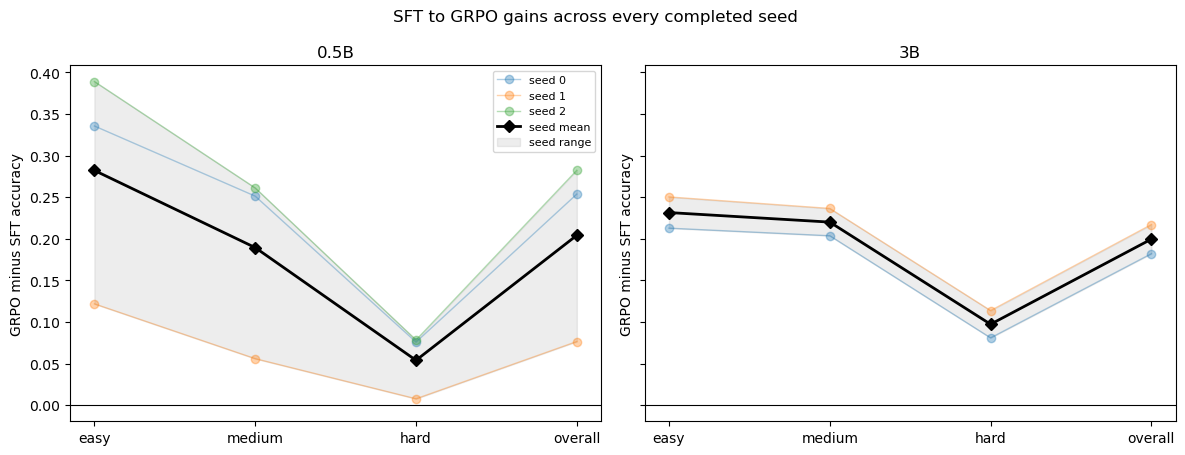

In [6]:
# print every available seed before calculating the scale summaries
groups = ["easy", "medium", "hard", "overall"]
gain_by_scale = {}
for scale, seed_runs in RUNS.items():
    gain_by_scale[scale] = {}
    for seed, data in seed_runs.items():
        sft = per_tier(data["sft"], TIERS)
        grpo = per_tier(data["grpo"], TIERS)
        sft["overall"] = np.mean([row["correct"] for row in data["sft"]])
        grpo["overall"] = np.mean([row["correct"] for row in data["grpo"]])
        gain_by_scale[scale][seed] = np.array([grpo[group] - sft[group] for group in groups])
        print(f"{scale} seed {seed}: GRPO " + "  ".join(f"{group} {grpo[group]:.3f}" for group in groups))
        print(f"{scale} seed {seed}: gain " + "  ".join(f"{group} {grpo[group]-sft[group]:+.3f}" for group in groups))
    control = per_tier(BASE_GRPO[scale], TIERS)
    control["overall"] = np.mean([row["correct"] for row in BASE_GRPO[scale]])
    print(f"{scale} base to GRPO seed 0: " + "  ".join(f"{group} {control[group]:.3f}" for group in groups))
    print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
x = np.arange(len(groups))
for ax, scale in zip(axes, ("0.5B", "3B")):
    values = np.vstack(list(gain_by_scale[scale].values()))
    for seed, seed_values in gain_by_scale[scale].items():
        ax.plot(x, seed_values, "o-", alpha=0.35, lw=1, label=f"seed {seed}")
    ax.plot(x, values.mean(axis=0), "D-", color="black", lw=2, label="seed mean")
    ax.fill_between(x, values.min(axis=0), values.max(axis=0), color="grey", alpha=0.14, label="seed range")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(groups)
    ax.set_title(scale)
    ax.set_ylabel("GRPO minus SFT accuracy")
axes[0].legend(fontsize=8)
fig.suptitle("SFT to GRPO gains across every completed seed")
fig.tight_layout()
fig.savefig(FIG / "fig_tier_seed_summary.png", dpi=300, bbox_inches="tight")
print("saved fig_tier_seed_summary")
plt.show()

## Robustness: same numbers under the original proposal grouping

In [7]:
# check both tier definitions for every completed seed
for scale, seed_runs in RUNS.items():
    for seed, data in seed_runs.items():
        for name, tiers in [("validated", TIERS), ("proposal ", TIERS_PROPOSAL)]:
            grpo = per_tier(data["grpo"], tiers)
            sft = per_tier(data["sft"], tiers)
            print(f"{scale} seed {seed} {name} " + "  ".join(
                f"{tier} {grpo[tier]-sft[tier]:+.3f}" for tier in ("easy", "medium", "hard")
            ))
        print()

0.5B seed 0 validated easy +0.336  medium +0.251  hard +0.076
0.5B seed 0 proposal  easy +0.341  medium +0.243  hard +0.076

0.5B seed 1 validated easy +0.122  medium +0.056  hard +0.008
0.5B seed 1 proposal  easy +0.125  medium +0.051  hard +0.008

0.5B seed 2 validated easy +0.389  medium +0.261  hard +0.078
0.5B seed 2 proposal  easy +0.386  medium +0.266  hard +0.078

3B seed 0 validated easy +0.213  medium +0.204  hard +0.081
3B seed 0 proposal  easy +0.213  medium +0.204  hard +0.081

3B seed 1 validated easy +0.250  medium +0.236  hard +0.114
3B seed 1 proposal  easy +0.255  medium +0.230  hard +0.114



## The mechanism figure: GRPO closes the measured expression gap

No tiers at all here. X = how much each subject's knowledge (probe) exceeds what the
base model expresses generatively, y = how much grpo improved that subject. If grpo
is an elicitation trainer, points should track the diagonal.

saved fig_mechanism_gap


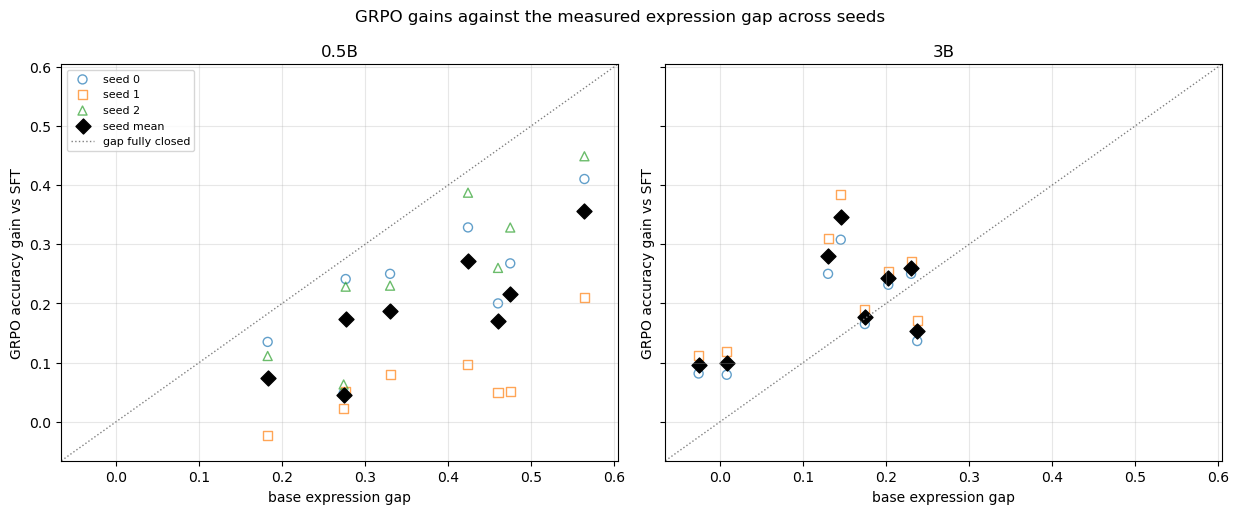

In [8]:
# keep the seed spread visible instead of hiding it in one pooled point
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharex=True, sharey=True)
seed_markers = ["o", "s", "^"]
seed_colors = ["tab:blue", "tab:orange", "tab:green"]
all_values = []
for ax, scale in zip(axes, ("0.5B", "3B")):
    knowledge = per_subject(PROBE[scale])
    base = per_subject(BASE[scale])
    x_values = np.array([knowledge[subject] - base[subject] for subject in all_subjects()])
    seed_values = []
    for marker, color, (seed, data) in zip(seed_markers, seed_colors, RUNS[scale].items()):
        grpo = per_subject(data["grpo"])
        sft = per_subject(data["sft"])
        y_values = np.array([grpo[subject] - sft[subject] for subject in all_subjects()])
        seed_values.append(y_values)
        ax.scatter(x_values, y_values, marker=marker, s=42, facecolors="none", edgecolors=color, alpha=0.7, label=f"seed {seed}")
        all_values.extend(x_values.tolist() + y_values.tolist())
    mean_values = np.vstack(seed_values).mean(axis=0)
    ax.scatter(x_values, mean_values, marker="D", s=58, color="black", label="seed mean")
    ax.set_title(scale)
    ax.set_xlabel("base expression gap")
    ax.set_ylabel("GRPO accuracy gain vs SFT")
    ax.grid(alpha=0.3)
limit_low = min(all_values) - 0.04
limit_high = max(all_values) + 0.04
for ax in axes:
    ax.plot([limit_low, limit_high], [limit_low, limit_high], ls=":", c="grey", lw=1, label="gap fully closed")
    ax.set_xlim(limit_low, limit_high)
    ax.set_ylim(limit_low, limit_high)
axes[0].legend(fontsize=8)
fig.suptitle("GRPO gains against the measured expression gap across seeds")
fig.tight_layout()
fig.savefig(FIG / "fig_mechanism_gap.png", dpi=300, bbox_inches="tight")
print("saved fig_mechanism_gap")
plt.show()